# Prototipo funcional — Avance al 18 de noviembre de 2026

**Proyecto Final I — Chatbot Inteligente mediante Aprendizaje Automático.**
Opción B: soporte técnico informático limitado a computadoras, celulares y
consolas. **Desarrollador principal: Sergio Adriel Muñoz Camarena.**
Corte de documentación: **18 de noviembre de 2026**; cada ejecución imprime su
propia fecha y la instantánea de datos utilizada.

**Entrega final prevista: 4 de diciembre de 2026.** Este documento presenta un
avance funcional que permite continuar incorporando datos y entrenamientos.

El equipo está integrado por Erick Mendoza Mendoza y Daniel Gibran Luciano
Tellez (construcción y revisión del dataset), Sergio Adriel Muñoz Camarena
(programación, gestor, interfaz e integración) y Raynier Jetsahe Torres Flores
(integración, entrenamiento, evaluación y verificación). La distribución de
responsabilidades corresponde a la indicada por el equipo; las aportaciones y
ejecuciones nuevas conservan su responsable y fecha reales.

La base contiene **240 ejemplos sintéticos, 16 intenciones y 15 ejemplos por
intención**, acumulados en **15 etapas**. Las fechas del escenario son simuladas;
no representan quince días de trabajo real. Los ejemplos revisados de
`data/team/` se agregan con su propia procedencia. El mínimo solicitado de 20
ejemplos por intención **no se cumple con la base sola**: faltan al menos 80
ejemplos pertinentes y diversos, cinco por categoría. No se completa esa
diferencia mediante duplicados.

Se evalúan **Naive Bayes** y **regresión logística**, con los mismos datos y
validación cruzada. Se documenta la versión seleccionada y se identifica su
estado provisional, aprobado o histórico. Las 80 consultas de referencia ya se han usado durante el
desarrollo: esta evaluación es reproducible, **no una nueva prueba final ciega**.
Se requiere otra prueba reservada para afirmar mejoras generalizables después
de los ajustes.

## Ejecutar

Desde la raíz: `python -m src.create_notebook`, o `reproducir-notebook.cmd`.
Python 3.12 y `requirements-lock.txt` identifican el entorno. Usa `notebook.cmd`
para abrirlo; en otra instalación, configura Jupyter con el repositorio completo.
No usa APIs de clasificación, claves privadas ni modelos lingüísticos descargados.
La ejecución escribe los artefactos `reports/current-*` y conserva los datos y
modelos anteriores.


In [1]:
from pathlib import Path
from hashlib import sha256
import sys, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from IPython import get_ipython
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'data/simulation.json').is_file() and (p/'src/current_experiment.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.preprocessing import normalize, tokenize
from src.current_experiment import build_current_experiment
get_ipython().run_line_magic('matplotlib', 'inline')
DOCUMENT_VERSION = '861484ac-3558-43d4-a997-959aeec83d47'
protected = ['data/simulation.json', 'data/test.csv', 'data/train.csv', 'web/model.json',
             'web/simulation/day-15.json', 'reports/metrics.json']
before_hashes = {name: sha256((ROOT/name).read_bytes()).hexdigest() for name in protected}
team = json.loads((ROOT/'docs/equipo.json').read_text(encoding='utf-8-sig'))
print('Python', platform.python_version(), '| scikit-learn', sklearn.__version__)
print('Proyecto:', ROOT.name)
display(pd.DataFrame(team['roles'])[['nombre', 'funcion', 'alcance']])


Python 3.12.10 | scikit-learn 1.7.2
Proyecto: yinyan-workshop


,nombre,funcion,alcance
0,Sergio Adriel Muñoz Camarena,Desarrollador principal,"Programación del chatbot, gestor de diálogo, i..."
1,Raynier Jetsahe Torres Flores,"Desarrollo, entrenamiento y evaluación","Integración, entrenamiento, comparación de cla..."
2,Erick Mendoza Mendoza,Construcción y revisión del dataset,"Ejemplos, expresiones lingüísticas, clasificac..."
3,Daniel Gibran Luciano Tellez,Construcción y revisión del dataset,"Ejemplos, organización del conjunto, revisión ..."


## 1. Instantánea y protocolo actual

La función siguiente **entrena y calcula** el experimento; no se limita a leer
métricas guardadas. Congela una instantánea de la base y las aportaciones
revisadas, compara dos clasificadores con cinco pliegues y evalúa ambos en las
80 consultas de referencia. Las celdas posteriores muestran las operaciones y
verifican su reproducción.

Cada vectorizador se ajusta solo con el entrenamiento del pliegue. Las etiquetas
de referencia no eligen el ganador de CV ni sustituyen silenciosamente el
clasificador activo de la plataforma.


In [2]:
experiment = build_current_experiment(write_outputs=True, version_id=DOCUMENT_VERSION)
snapshot = experiment['snapshot_data']
active_model = experiment['active_model']
train = pd.DataFrame(snapshot['training_examples'])
test = pd.DataFrame(snapshot['evaluation'])
labels = sorted(train.intent.unique())
print('Ejecución:', experiment['generated_at'])
print('Conteos:', experiment['counts'])
print('Modelo activo:', experiment['active_model'], '| ganador de CV:', experiment['cv_winner'])
print('Versión documentada:', experiment.get('version_id', 'base de referencia'))
print('Versión del dataset:', experiment.get('dataset_version', experiment['hashes'].get('training_snapshot_sha256')))
print('Procedencia:', experiment['provenance'])
display(experiment['protocol'])
display(train[['text', 'intent']].head(8))


Ejecución: 2026-11-18T19:00:45.060Z
Conteos: {'base': 240, 'additional': 0, 'total': 240, 'test': 80, 'intents': 16, 'per_intent': {'almacenamiento': 15, 'ayuda': 15, 'carga': 15, 'conexion': 15, 'contacto': 15, 'controles': 15, 'despedida': 15, 'encendido': 15, 'liquidos': 15, 'pantalla': 15, 'presupuesto': 15, 'rendimiento': 15, 'saludo': 15, 'software': 15, 'sonido': 15, 'temperatura': 15}}
Modelo activo: logistic_regression | ganador de CV: logistic_regression
Versión documentada: 861484ac-3558-43d4-a997-959aeec83d47
Versión del dataset: fe8a9f036c9034573f51a2848d51b7adeb8a8d636a23c49f2842c1033b8a4105
Procedencia: {'base': 'Base sintética conservada, con sus fechas originales.', 'additional': 'Solo aportaciones aprobadas presentes en la instantánea de esta jornada.', 'evaluation': 'Benchmark de desarrollo conocido; no es el conjunto final reservado.', 'timestamps': 'Fecha real de ejecución de la jornada.'}


{'seed': 42,
 'cv': 'StratifiedKFold(5, shuffle=True, random_state=42)',
 'selection': 'Mayor F1 macro medio de validación cruzada; empate: regresión logística.',
 'parameters': {'naive_bayes': {'alpha': 0.25},
  'logistic_regression': {'C': 8.0, 'max_iter': 2000}},
 'evaluation_policy': '80 consultas conocidas de desarrollo; el conjunto final reservado no participa en entrenamiento ni selección.'}

,text,intent
0,hola,saludo
1,adios,despedida
2,ayuda,ayuda
3,no prende,encendido
4,no carga,carga
5,se calienta,temperatura
6,esta lenta,rendimiento
7,no hay internet,conexion


## 2. Exploración y requisito de ejemplos

Los conteos corresponden a la instantánea actual, no al corpus anterior de 384
frases. Los faltantes por intención orientan el trabajo del equipo. Los ejemplos
deben aportar diversidad y categorías correctas. La base sintética requiere revisión humana; no contiene consultas de clientes reales
ni acredita sesiones históricas de estudiantes.


,ejemplos,faltan_para_20
intent,,
almacenamiento,15,5
ayuda,15,5
carga,15,5
conexion,15,5
contacto,15,5
controles,15,5
despedida,15,5
encendido,15,5
liquidos,15,5


Mínimo por categoría: 15
¿Todas tienen al menos 20?: False
Ejemplos faltantes: 80


{'minimum_training': 200,
 'minimum_intents': 10,
 'minimum_per_intent': 20,
 'minimum_test': 50,
 'training_total_met': True,
 'intents_met': True,
 'per_intent_met': False,
 'test_total_met': False,
 'per_intent_missing': {'almacenamiento': 5,
  'ayuda': 5,
  'carga': 5,
  'conexion': 5,
  'contacto': 5,
  'controles': 5,
  'despedida': 5,
  'encendido': 5,
  'liquidos': 5,
  'pantalla': 5,
  'presupuesto': 5,
  'rendimiento': 5,
  'saludo': 5,
  'software': 5,
  'sonido': 5,
  'temperatura': 5},
 'missing_examples_total': 80}

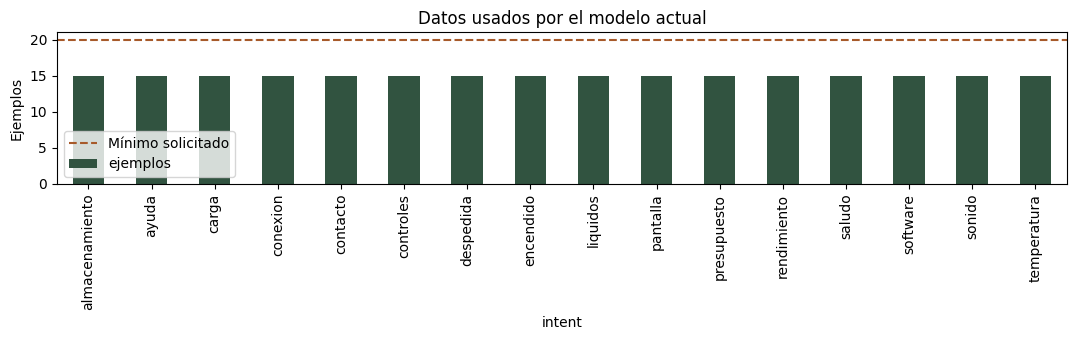

In [3]:
distribution = train.groupby('intent').size().reindex(labels).rename('ejemplos').to_frame()
distribution['faltan_para_20'] = (20 - distribution.ejemplos).clip(lower=0)
display(distribution)
assert len(train) >= 200 and len(labels) >= 10 and len(test) >= 50
print('Mínimo por categoría:', int(distribution.ejemplos.min()))
print('¿Todas tienen al menos 20?:', bool((distribution.ejemplos >= 20).all()))
print('Ejemplos faltantes:', int(distribution.faltan_para_20.sum()))
display(experiment['requirements'])
ax = distribution.ejemplos.plot.bar(figsize=(11, 3.5), color='#315340', title='Datos usados por el modelo actual')
ax.axhline(20, color='#a75a2a', linestyle='--', label='Mínimo solicitado')
ax.set_ylabel('Ejemplos'); ax.legend(); plt.tight_layout(); plt.show()


## 3. Preparación del lenguaje natural

Minúsculas, descomposición Unicode NFD y eliminación de diacríticos;
tokenización `[a-z0-9]+`; filtrado de palabras funcionales y lematización ligera
mediante un diccionario explícito. Se conserva **no** para distinguir síntomas.
El diccionario tiene cobertura limitada, no es un analizador completo de español.
El navegador recibe la misma lista y mapa de lemas junto con cada modelo.


In [4]:
for text in ['¡MI TELÉFONO NO CARGA!', 'Las pantallas están rotas',
             'La laptop se está calentando', 'Mi computadora no detecta redes']:
    print(text, '\n  normalizado:', normalize(text), '\n  tokens:', tokenize(text))
assert 'no' in tokenize('Mi teléfono no carga')
train_keys = train.text.map(lambda value: ' '.join(tokenize(value)))
test_keys = test.text.map(lambda value: ' '.join(tokenize(value)))
print('Duplicados normalizados dentro de entrenamiento:', int(train_keys.duplicated().sum()))
print('Coincidencias normalizadas entrenamiento/referencia:', len(set(train_keys) & set(test_keys)))
assert not (set(train_keys) & set(test_keys)), 'La referencia aparece en entrenamiento'


¡MI TELÉFONO NO CARGA! 
  normalizado: ¡mi telefono no carga! 
  tokens: ['telefono', 'no', 'cargar']
Las pantallas están rotas 
  normalizado: las pantallas estan rotas 
  tokens: ['pantalla', 'estan', 'roto']
La laptop se está calentando 
  normalizado: la laptop se esta calentando 
  tokens: ['laptop', 'calentar']
Mi computadora no detecta redes 
  normalizado: mi computadora no detecta redes 
  tokens: ['computadora', 'no', 'detecta', 'red']
Duplicados normalizados dentro de entrenamiento: 0
Coincidencias normalizadas entrenamiento/referencia: 0


## 4. Representación TF-IDF

Unigramas y bigramas, frecuencia sublineal `1 + ln(tf)`, IDF suavizado y norma
L2. Los bigramas conservan relaciones locales y las palabras conocidas permiten
representar combinaciones nuevas. El modelo no comprende por sí solo causalidad,
metáforas ni términos ausentes del vocabulario.

Esta matriz es exploratoria: cada pipeline de validación crea otro vectorizador.


In [5]:
def make_pipeline(classifier):
    return Pipeline([
        ('tfidf', TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                                 ngram_range=(1, 2), sublinear_tf=True, norm='l2', smooth_idf=True)),
        ('classifier', classifier),
    ])

exploratory = make_pipeline(MultinomialNB(alpha=0.25)).named_steps['tfidf']
X = exploratory.fit_transform(train.text)
print('Forma:', X.shape, '| densidad:', X.nnz / (X.shape[0] * X.shape[1]))
print('Primeros términos:', exploratory.get_feature_names_out()[:25])


Forma: (240, 1108) | densidad: 0.005640794223826715
Primeros términos: ['abren' 'abren paginas' 'abrir' 'abrir nada' 'abrir programa' 'abro'
 'abro varias' 'acaba' 'acaba rapidisimo' 'accidente' 'acepta'
 'acepta contrasena' 'actualizacion' 'actualizacion sistema' 'actualizar'
 'adaptador' 'adaptador red' 'adentro' 'adios' 'agarra' 'agarra wifi'
 'agradesco' 'agradesco orientacion' 'agua' 'agua compu']


## 5. Dos clasificadores y validación comparable

Naive Bayes multinomial (`alpha=0.25`) y regresión logística (`C=8`,
`max_iter=2000`) usan cinco pliegues estratificados, semilla 42 y la misma
representación. No se realizó una búsqueda exhaustiva de parámetros.
La celda vuelve a ejecutar CV explícitamente y verifica el resultado.

El mayor F1 macro medio identifica al ganador. La aplicación mantiene Naive Bayes
para la práctica acumulativa. Si otro modelo gana CV, debe explicarse esa
diferencia de selección e integración; no se afirma que el activo sea óptimo.


In [6]:
pipelines = {
    'naive_bayes': make_pipeline(MultinomialNB(alpha=0.25)),
    'logistic_regression': make_pipeline(LogisticRegression(C=8.0, max_iter=2000, random_state=42)),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, pipeline in pipelines.items():
    values = cross_validate(pipeline, train.text, train.intent, cv=folds,
                            scoring={'f1_macro': 'f1_macro', 'accuracy': 'accuracy'}, n_jobs=1)
    cv_results[name] = {'f1_macro_mean': float(values['test_f1_macro'].mean()),
                        'f1_macro_std': float(values['test_f1_macro'].std()),
                        'accuracy_mean': float(values['test_accuracy'].mean())}
    for metric, value in cv_results[name].items():
        assert abs(value - experiment['cv'][name][metric]) < 1e-10
display(pd.DataFrame(cv_results).T)
winner = max(cv_results, key=lambda name: cv_results[name]['f1_macro_mean'])
assert winner == experiment['cv_winner']
print('Ganador por CV:', winner, '| activo en la plataforma:', experiment['active_model'])


,f1_macro_mean,f1_macro_std,accuracy_mean
naive_bayes,0.417239,0.075505,0.425000
logistic_regression,0.456241,0.056610,0.470833


Ganador por CV: logistic_regression | activo en la plataforma: logistic_regression


## 6. Referencia de 80 consultas y matrices de confusión

Se ajustan ambos clasificadores con todo el entrenamiento. Accuracy es la
fracción de etiquetas correctas; precision, recall y F1 macro promedian por
categoría. La tabla usa la clase de mayor probabilidad, sin rechazo. Esta
referencia ya se utilizó durante el desarrollo; no es otra prueba final ciega.
La cobertura conversacional se informa aparte.


,accuracy,precision_macro,recall_macro,f1_macro
naive_bayes,0.8625,0.881101,0.8625,0.859975
logistic_regression,0.8750,0.895313,0.8750,0.873393


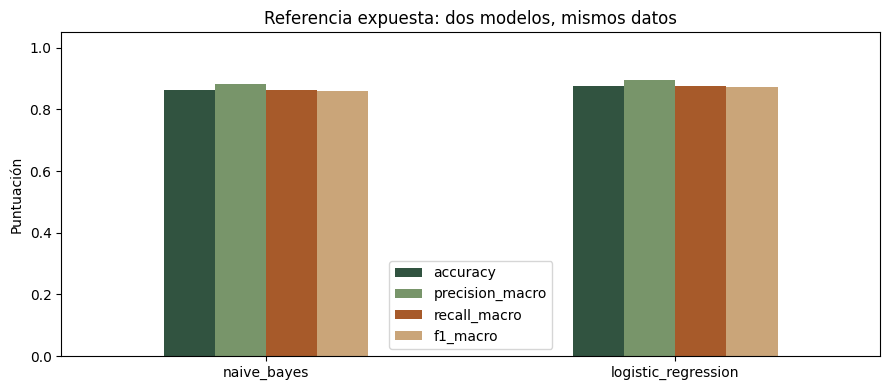

In [7]:
metric_names = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
predictions, observed = {}, {}
for name, pipeline in pipelines.items():
    pipeline.fit(train.text, train.intent)
    prediction = pipeline.predict(test.text)
    predictions[name] = prediction
    precision, recall, f1, _ = precision_recall_fscore_support(
        test.intent, prediction, average='macro', zero_division=0)
    observed[name] = dict(zip(metric_names, map(float, [accuracy_score(test.intent, prediction), precision, recall, f1])))
    for metric in metric_names:
        assert abs(observed[name][metric] - experiment['models'][name][metric]) < 1e-10
comparison = pd.DataFrame(observed).T
display(comparison)
comparison.plot.bar(figsize=(9, 4), ylim=(0, 1.05), rot=0, color=['#315340', '#78956a', '#a75a2a', '#caa579'])
plt.ylabel('Puntuación'); plt.title('Referencia expuesta: dos modelos, mismos datos'); plt.tight_layout(); plt.show()


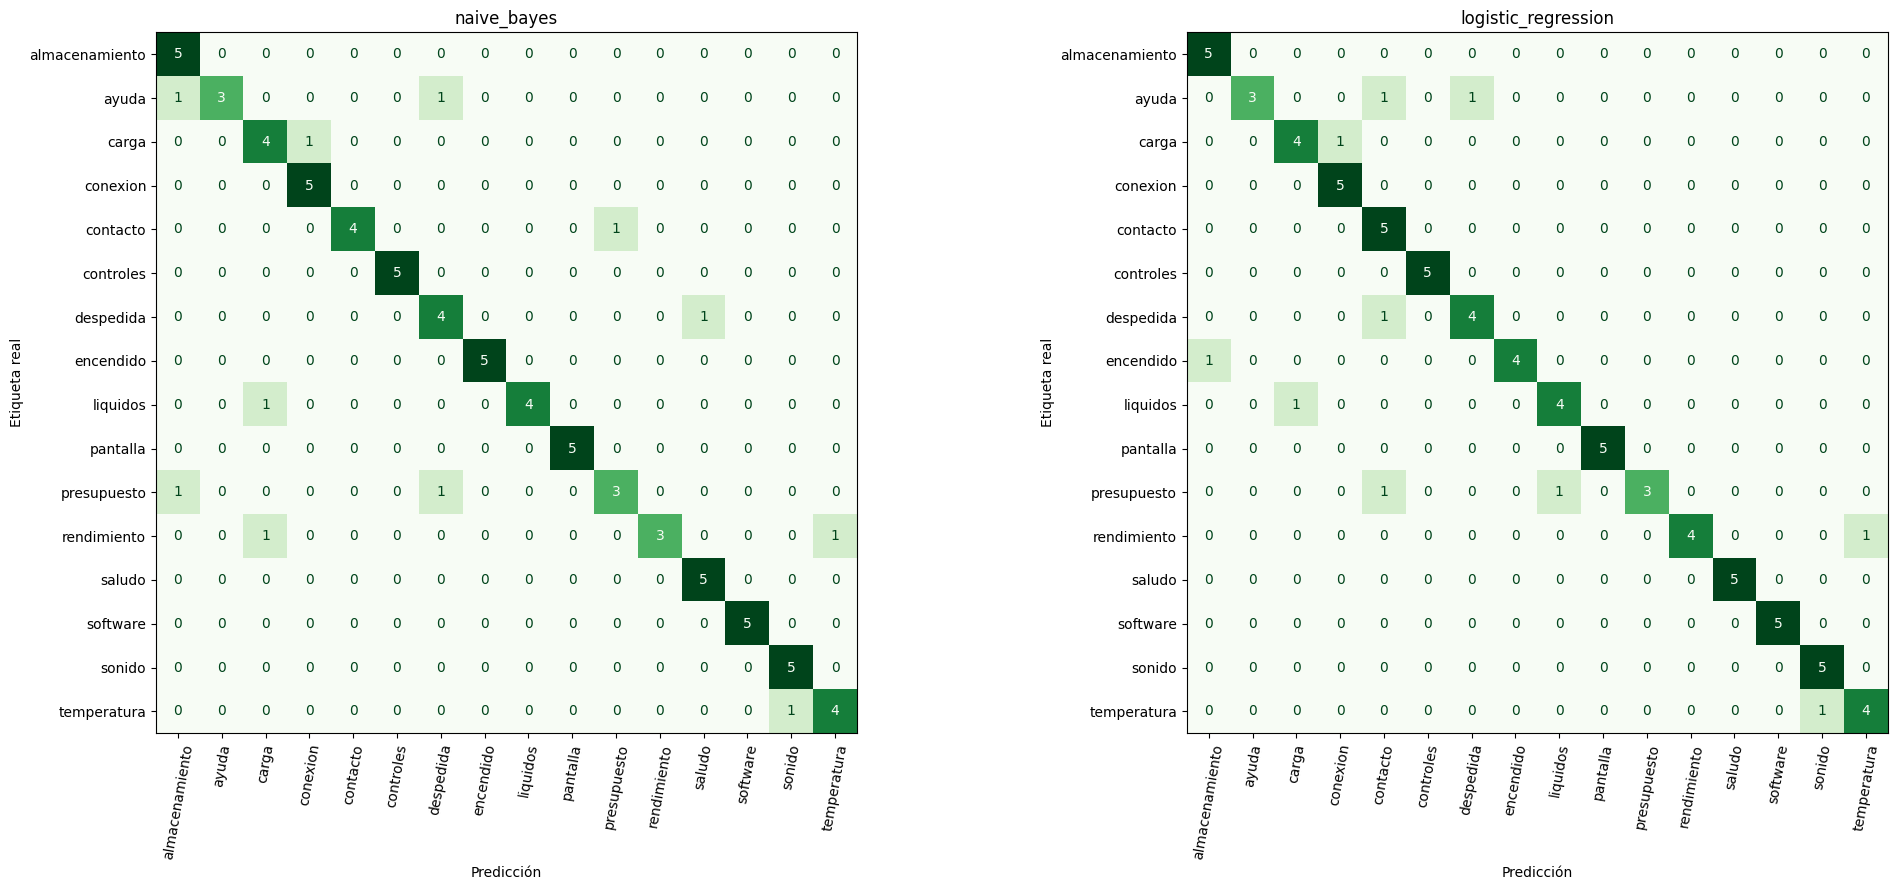

,precision,recall,f1-score,support
almacenamiento,0.833333,1.000,0.909091,5.000
ayuda,1.000000,0.600,0.750000,5.000
carga,0.800000,0.800,0.800000,5.000
conexion,0.833333,1.000,0.909091,5.000
contacto,0.625000,1.000,0.769231,5.000
controles,1.000000,1.000,1.000000,5.000
despedida,0.800000,0.800,0.800000,5.000
encendido,1.000000,0.800,0.888889,5.000
liquidos,0.800000,0.800,0.800000,5.000
pantalla,1.000000,1.000,1.000000,5.000


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(21, 9))
for ax, (name, prediction) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(test.intent, prediction, labels=labels,
        display_labels=labels, xticks_rotation=80, cmap='Greens', colorbar=False, ax=ax)
    ax.set_title(name); ax.set_xlabel('Predicción'); ax.set_ylabel('Etiqueta real')
plt.tight_layout(); plt.show()
display(pd.DataFrame(experiment['models'][active_model]['per_class']).T)


## 7. Quince etapas acumulativas

Cada etapa incorpora 16 ejemplos, uno por intención, hasta llegar a 240. La curva
de Naive Bayes se verifica contra la práctica entregada. Las aportaciones
posteriores no reescriben estas etapas. Los horarios y perfiles ficticios de la
base no acreditan quince días de sesiones reales ni participación de personas.


,day,total_examples,correct,total,accuracy,precision_macro,accepted
0,1,16,13,80,0.1625,0.478877,3
1,2,32,20,80,0.2500,0.517893,9
2,3,48,26,80,0.3250,0.500050,10
3,4,64,35,80,0.4375,0.566535,10
4,5,80,44,80,0.5500,0.606250,9
5,6,96,50,80,0.6250,0.663025,11
6,7,112,50,80,0.6250,0.635119,16
7,8,128,53,80,0.6625,0.686086,17
8,9,144,54,80,0.6750,0.697504,20
9,10,160,61,80,0.7625,0.822917,21


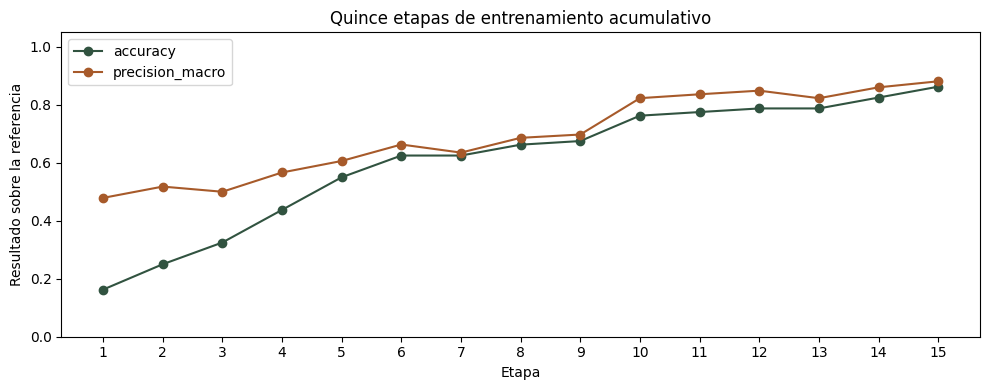

In [9]:
curve = pd.DataFrame(experiment['curve'])
assert list(curve.day) == list(range(1, 16))
assert bool(experiment['curve_verified'])
display(curve[['day', 'total_examples', 'correct', 'total', 'accuracy', 'precision_macro', 'accepted']])
ax = curve.plot(x='day', y=['accuracy', 'precision_macro'], marker='o', figsize=(10, 4),
                ylim=(0, 1.05), color=['#315340', '#a75a2a'], title='Quince etapas de entrenamiento acumulativo')
ax.set_xlabel('Etapa'); ax.set_ylabel('Resultado sobre la referencia'); ax.set_xticks(range(1, 16))
plt.tight_layout(); plt.show()


## 8. Errores del modelo activo y rechazo

Se muestran errores observados del clasificador seleccionado. La interpretación vincula
la consulta, su categoría y la predicción con las limitaciones léxicas; se
escogen tres categorías distintas cuando hay suficientes errores.

Una clase correcta de máxima probabilidad puede ser rechazada por baja confianza.
La cobertura y los aciertos entre aceptadas explican lo que ve el usuario.
Las probabilidades no están calibradas y los umbrales son heurísticos.


In [10]:
errors = [row for row in experiment['errors'] if row['model'] == active_model]
print('Errores observados del modelo activo:', len(errors))
if errors:
    display(pd.DataFrame(errors)[['text', 'expected', 'predicted', 'interpretation']])
    selected_errors, covered = [], set()
    for error in errors:
        if error['expected'] not in covered:
            selected_errors.append(error); covered.add(error['expected'])
        if len(selected_errors) == 3: break
    for error in selected_errors:
        print('\nConsulta:', error['text'])
        print('Esperada:', error['expected'], '| predicha:', error['predicted'])
        print('Interpretación:', error['interpretation'])
else:
    print('No hubo errores en esta instantánea de referencia; esto no garantiza generalización.')
acceptance = experiment['acceptance']
display(acceptance)
print('Cobertura:', acceptance['accepted'] / acceptance['total'])
print('Acierto entre aceptadas:', acceptance['correct_accepted'] / acceptance['accepted'] if acceptance['accepted'] else 'sin aceptadas')
gap = {name: observed[name]['f1_macro'] - cv_results[name]['f1_macro_mean'] for name in pipelines}
print('Diferencia F1 referencia - F1 medio de CV:', gap)
print('La distancia entre CV y referencia exige cautela: no demuestra robustez ante consultas reales.')


Errores observados del modelo activo: 10


,text,expected,predicted,interpretation
0,"Hasta otra ocasión, taller",despedida,contacto,Un cierre indirecto sin fórmulas habituales pu...
1,¿Qué consultas de soporte admites?,ayuda,contacto,Las peticiones generales y la cortesía compart...
2,¿Cuál es el alcance de tu orientación?,ayuda,despedida,Las peticiones generales y la cortesía compart...
3,Al presionar power mi portátil sigue completam...,encendido,almacenamiento,Una paráfrasis de falta de arranque puede conf...
4,Mi portátil pierde toda la autonomía al quitar...,carga,conexion,La dependencia del cable puede expresarse sin ...
5,Sale una advertencia térmica en medio de mis p...,temperatura,sonido,La causa térmica puede describirse mediante me...
6,Los cuadros por segundo bajan mucho cuando jue...,rendimiento,temperatura,La lentitud se expresa con metáforas y efectos...
7,Volqué mi taza de té sobre el portátil,liquidos,carga,Una bebida o situación nueva puede no comparti...
8,¿Hay que pagar por que revisen el equipo?,presupuesto,liquidos,Una solicitud de precio puede incluir el sínto...
9,Quisiera que me cotizaran un cambio de pieza,presupuesto,contacto,Una solicitud de precio puede incluir el sínto...



Consulta: Hasta otra ocasión, taller
Esperada: despedida | predicha: contacto
Interpretación: Un cierre indirecto sin fórmulas habituales puede carecer de las señales léxicas aprendidas. Resultado observado: contacto; etiqueta esperada: despedida.

Consulta: ¿Qué consultas de soporte admites?
Esperada: ayuda | predicha: contacto
Interpretación: Las peticiones generales y la cortesía comparten palabras; la intención pragmática depende de la frase completa. Resultado observado: contacto; etiqueta esperada: ayuda.

Consulta: Al presionar power mi portátil sigue completamente apagada
Esperada: encendido | predicha: almacenamiento
Interpretación: Una paráfrasis de falta de arranque puede confundirse con síntomas de carga o pantalla. Resultado observado: almacenamiento; etiqueta esperada: encendido.


{'accepted': 54,
 'total': 80,
 'correct_accepted': 51,
 'coverage': 0.675,
 'accuracy_among_accepted': 0.9444444444444444}

Cobertura: 0.675
Acierto entre aceptadas: 0.9444444444444444
Diferencia F1 referencia - F1 medio de CV: {'naive_bayes': 0.4427357364857365, 'logistic_regression': 0.4171515984015984}
La distancia entre CV y referencia exige cautela: no demuestra robustez ante consultas reales.


## 9. Integración, diálogo y colaboración

La aplicación carga la última versión aprobada. Cada entrenamiento crea una
jornada con instantánea de datos y ambos modelos, conservando versiones previas.
El resultado nuevo es provisional hasta revisar sus comprobaciones y activarlo.
Sin una versión aprobada se conserva el modelo base de referencia.
`web/ml.js` aplica los parámetros exportados. `web/dialogue.js` conserva equipo,
falla, etapa y respuestas; el estado modifica las preguntas y el resumen durante
tres turnos. Las reglas atienden controles, respuestas cortas, elecciones y
alertas; el clasificador determina las intenciones ordinarias.

Antes del turno se usa `recibir-aportes.cmd`; luego `iniciar.cmd`, responsable,
consultas y revisión de categorías. Los ejemplos empiezan pendientes; solo los
aprobados entran en la siguiente jornada. `subir-aportes.cmd` confirma y envía
`data/team/`. Se conserva la hora de cada consulta. Los modelos personalizados
siguen locales y se reentrenan después de recibir ejemplos. Las predicciones
del propio bot no se incorporan automáticamente como etiquetas correctas.

La evidencia siguiente corresponde al modelo base con la misma configuración
de la página; no representa sesiones de alumnos. Se regenera con
`node scripts/check-current-dialogue.mjs`. La suite general usa
`node --test tests/*.test.mjs`. La ausencia de evidencia se informa sin inventarla.


In [11]:
evidence_path = ROOT/'reports/current-dialogue-results.json'
if evidence_path.is_file():
    evidence = json.loads(evidence_path.read_text(encoding='utf-8-sig'))
    print('Evidencia de diálogo:', evidence_path.relative_to(ROOT))
    print(evidence.get('scope', ''))
    print('Pruebas aprobadas:', evidence.get('passed'), '/', evidence.get('total'))
    display(evidence.get('cases', []))
    display(evidence)
else:
    print('No hay evidencia actual de diálogo adjunta; ejecutar las pruebas Node por separado.')


Evidencia de diálogo: reports\current-dialogue-results.json
Pruebas funcionales de la versión documentada con el modo de la página; no son sesiones de alumnos ni una prueba final inédita.
Pruebas aprobadas: 7 / 7


[{'name': 'Tres turnos de encendido utilizan equipo y respuestas previas',
  'passed': True},
 {'name': 'Tres turnos de carga utilizan la comprobación del cable',
  'passed': True},
 {'name': 'Una expresión ambigua solicita aclaración', 'passed': True},
 {'name': 'Una receta fuera del dominio no se contesta como soporte',
  'passed': True},
 {'name': 'El parpadeo se aclara y conserva el celular durante tres turnos',
  'passed': True},
 {'name': 'Reiniciar elimina equipo, falla y respuestas pendientes',
  'passed': True},
 {'name': 'El contexto de líquido conserva la precaución', 'passed': True}]

{'generated_at': '2026-11-18T19:01:47.910Z',
 'model_path': 'C:\\Users\\Adriel\\Downloads\\yinyan-workshop-local-windows\\yinyan-workshop\\data\\training\\runs\\861484ac-3558-43d4-a997-959aeec83d47\\model.json',
 'version_id': '861484ac-3558-43d4-a997-959aeec83d47',
 'model_sha256': '9b3fd9bf45719823a5a0d044ae5e886e55b69835d28a196313fae3f1c6b1aa62',
 'configuration': {'concise': True},
 'scope': 'Pruebas funcionales de la versión documentada con el modo de la página; no son sesiones de alumnos ni una prueba final inédita.',
 'total': 7,
 'passed': 7,
 'failed': 0,
 'cases': [{'name': 'Tres turnos de encendido utilizan equipo y respuestas previas',
   'passed': True},
  {'name': 'Tres turnos de carga utilizan la comprobación del cable',
   'passed': True},
  {'name': 'Una expresión ambigua solicita aclaración', 'passed': True},
  {'name': 'Una receta fuera del dominio no se contesta como soporte',
   'passed': True},
  {'name': 'El parpadeo se aclara y conserva el celular durante tres t

## 10. Comprobaciones y conclusiones

Los hashes verifican que el experimento no reemplazó datos ni modelos
protegidos. Sin aportaciones adicionales, el Naive Bayes reproducido debe
coincidir con el modelo de etapa 15 y su exactitud publicada. Con ejemplos
nuevos, las métricas corresponden a la instantánea identificada.

**Pendientes de datos y evaluación final:** ampliar las 15 muestras por intención
de la base hasta al menos 20, revisar su diversidad y aportar una prueba final
reservada con al menos 50 expresiones nuevas. La referencia de 80 ya conocida
sigue siendo un benchmark de desarrollo. La baja CV respecto a esa referencia y
las probabilidades sin calibración limitan la interpretación de sus resultados.
Las frases indirectas y las fallas múltiples pueden producir rechazo o error.
El gestor conserva tres variantes también en el modo breve, mantiene el contexto
y solicita aclaración cuando no hay evidencia suficiente.

El chatbot orienta comprobaciones externas; no confirma componentes dañados ni
la eficacia de una reparación. Todos los integrantes deben comprender los dos
clasificadores, el preprocesamiento, las métricas y el gestor para la demostración.

Referencias oficiales: [extracción de texto](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction),
[filtración de datos](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage),
[regresión logística](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression),
[Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html#multinomial-naive-bayes).


In [12]:
after_hashes = {name: sha256((ROOT/name).read_bytes()).hexdigest() for name in protected}
assert before_hashes == after_hashes, 'Se modificó un archivo protegido'
display(experiment['hashes'])
export_path = Path(experiment.get('model_path') or ROOT/'web/simulation/day-15.json')
exported = json.loads(export_path.read_text(encoding='utf-8'))
fitted = pipelines[active_model]
vectorizer, classifier = fitted.named_steps['tfidf'], fitted.named_steps['classifier']
assert vectorizer.get_feature_names_out().tolist() == exported['features']
assert np.allclose(vectorizer.idf_, exported['idf'], rtol=0, atol=1e-12)
weights = classifier.feature_log_prob_ if active_model == 'naive_bayes' else classifier.coef_
assert np.allclose(weights, exported['weights'], rtol=0, atol=1e-12)
assert winner == experiment['cv_winner']
print('Modelo y vectorizador reproducidos coinciden con la versión documentada:', export_path.name)
print('CV, dos modelos y métricas reproducidos. No se alteraron datos ni modelos protegidos.')


{'base_file_sha256': '7af90b4134f51e9fa01c144f11f981078029a177df1001493b85818404c64e08',
 'evaluation_file_sha256': '946a397dd8acc1ec3f1b8c0aeda90008567235ae41389030033ed831e0673271',
 'training_snapshot_sha256': '0e8c943abe61935090b555d15f155d724eefbd2d3f18e7cdd39c40ee728711c1',
 'preprocessing_sha256': '44957ef65209bbc557d9d8b706c85cad797ec41fab1dd7e37f1048cb05df11f6'}

Modelo y vectorizador reproducidos coinciden con la versión documentada: model.json
CV, dos modelos y métricas reproducidos. No se alteraron datos ni modelos protegidos.
